# 04 — Survey-weighted validation and calibration

Fixed primary cohort: adults 20+ with explicit no prior diagnosis, observed HbA1c and complete CBC, applying notebook 03's medication/pregnancy rules. This notebook fits four weighted classifiers and development-only sigmoid calibrators using five outer and three inner PSU-grouped folds. The 95%-sensitivity development target is exploratory.

Run from the repository root or `notebooks/` with `requirements.txt` installed. Equivalent script: `python scripts/analysis/weighted_calibration_analysis.py`. Outputs: `results/weighted_calibration/`; generated interpretation: `docs/findings/weighted_calibration_analysis.md`.

**Uncertainty boundary:** the stratified delete-one-PSU intervals condition on fixed out-of-fold predictions and thresholds; they do not include retraining variability. Public pregnancy data and complete-case selection limit population claims. All outer folds are exploratory internal validation, not an untouched final test.

[CDC design/domain variance guidance](https://wwwn.cdc.gov/nchs/nhanes/tutorials/varianceestimation.aspx), [phlebotomy weights](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/GHB_L.htm), [calibration guidance](https://scikit-learn.org/stable/modules/calibration.html).

## Load fixed cohort and full survey design

In [1]:
from pathlib import Path
import json
import numpy as np
import pandas as pd
import matplotlib
matplotlib.use('Agg')
import matplotlib.pyplot as plt
from scipy.sparse import csr_matrix
from scipy.special import logit
from scipy.stats import t as student_t
from sklearn.compose import ColumnTransformer
from sklearn.pipeline import Pipeline
from sklearn.impute import SimpleImputer
from sklearn.preprocessing import StandardScaler, OneHotEncoder, FunctionTransformer
from sklearn.linear_model import LogisticRegression
from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import StratifiedGroupKFold
from sklearn.metrics import roc_auc_score, average_precision_score, confusion_matrix, log_loss

ROOT = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p / 'CODEX.md').is_file())
OUT = ROOT / 'results/weighted_calibration'
OUT.mkdir(parents=True, exist_ok=True)
RAW = ROOT / 'data/raw/2021_2023'
CBC = ['LBXWBCSI', 'LBXRBCSI', 'LBXHGB', 'LBXHCT', 'LBXMCVSI', 'LBXRDW',
       'LBXPLTSI', 'LBXLYPCT', 'LBXNEPCT', 'LBXMOPCT', 'LBXEOPCT', 'LBXBAPCT']
NUM = ['RIDAGEYR', 'INDFMPIR']
CAT = ['RIAGENDR', 'RIDRETH3', 'DMDEDUC2']

def read(name):
    d = pd.read_sas(RAW / f'{name}_L.xpt', format='xport')
    assert d.SEQN.is_unique
    for c in d.select_dtypes(include='number'):
        d.loc[d[c].abs().lt(1e-70), c] = 0.
    return d

demo, cbc, ghb, diq = [read(n) for n in ['DEMO', 'CBC', 'GHB', 'DIQ']]
full = demo.merge(ghb[['SEQN', 'WTPH2YR', 'LBXGH']], on='SEQN', how='left', validate='one_to_one')
full = full.merge(cbc[['SEQN'] + CBC], on='SEQN', how='left', validate='one_to_one')
full = full.merge(diq[['SEQN', 'DIQ010', 'DIQ050', 'DIQ070']], on='SEQN', how='left', validate='one_to_one')
assert len(full) == len(demo)
full['DMDEDUC2'] = full.DMDEDUC2.replace({7: np.nan, 9: np.nan})
preg_band = full.RIAGENDR.eq(2) & full.RIDAGEYR.between(20, 44)
keep = (full.RIDSTATR.eq(2) & full.WTPH2YR.gt(0) & full.RIDAGEYR.ge(20)
        & full.DIQ010.eq(2) & ~full.DIQ050.eq(1) & ~full.DIQ070.eq(1)
        & ~full.RIDEXPRG.eq(1) & (~preg_band | full.RIDEXPRG.eq(2))
        & full[['LBXGH'] + CBC].notna().all(axis=1))
d = full.loc[keep].reset_index(drop=True)
y = d.LBXGH.ge(6.5).astype(int).to_numpy()
w = d.WTPH2YR.to_numpy()
assert len(d) == 4612 and y.sum() == 106
previous = ROOT / 'results/cohort/cohort_oof_predictions.csv'
if previous.exists():
    old = pd.read_csv(previous)
    assert set(old.loc[old.cohort.eq('primary_adults20_no_diagnosis'), 'SEQN']) == set(d.SEQN)
assert np.isfinite(w).all() and (w > 0).all()
assert d[['SDMVSTRA', 'SDMVPSU']].notna().all().all()
groups = (d.SDMVSTRA.astype(int).astype(str) + ':' + d.SDMVPSU.astype(int).astype(str)).to_numpy()
# Preserve full positive-weight survey design before defining the analytic domain.
design = full.loc[full.WTPH2YR.gt(0), ['SDMVSTRA', 'SDMVPSU']].drop_duplicates()
assert design.notna().all().all()
strata = {int(h): sorted(g.SDMVPSU.astype(int).tolist()) for h, g in design.groupby('SDMVSTRA')}
assert all(len(psus) >= 2 for psus in strata.values())
design.to_csv(OUT / 'full_design_psus.csv', index=False)
print(f'Fixed cohort: {len(d)} participants, {y.sum()} positives; {len(strata)} strata, {len(design)} PSUs', flush=True)

Fixed cohort: 4612 participants, 106 positives; 15 strata, 30 PSUs


## Weighted nested validation

In [2]:
def make_model(nums, cats, forest):
    transform = [('num', Pipeline([('impute', SimpleImputer(strategy='median')),
                                  ('scale', StandardScaler())]), nums)]
    if cats:
        transform.append(('cat', Pipeline([('impute', SimpleImputer(strategy='most_frequent')),
            ('encode', OneHotEncoder(handle_unknown='ignore', sparse_output=False))]), cats))
    steps = [('pre', ColumnTransformer(transform))]
    if not forest:
        steps.append(('sparse', FunctionTransformer(csr_matrix, accept_sparse=True)))
    # Population-risk fitting: no class balancing on top of survey weights.
    clf = (RandomForestClassifier(n_estimators=300, min_samples_leaf=5, random_state=42, n_jobs=1)
           if forest else LogisticRegression(solver='liblinear', max_iter=2000))
    return Pipeline(steps + [('clf', clf)])

def fit_model(train, nums, cats, forest):
    model = make_model(nums, cats, forest)
    train_w = w[train] / w[train].mean()
    model.fit(d.iloc[train][nums + cats], y[train], clf__sample_weight=train_w)
    return model

def logits(scores):
    return csr_matrix(logit(np.clip(scores, 1e-6, 1-1e-6)).reshape(-1, 1))

def choose_threshold(labels, scores, weights, sensitivity_goal=.95):
    # Largest threshold retaining at least the prespecified weighted sensitivity.
    positive_scores = scores[labels == 1]
    positive_weights = weights[labels == 1]
    order = np.argsort(-positive_scores, kind='stable')
    cumulative = np.cumsum(positive_weights[order]) / positive_weights.sum()
    return float(positive_scores[order][np.flatnonzero(cumulative >= sensitivity_goal)[0]])

specs = {'age_logistic': (['RIDAGEYR'], [], False),
         'demographics_logistic': (NUM, CAT, False),
         'cbc_demographics_logistic': (NUM + CBC, CAT, False),
         'cbc_demographics_forest': (NUM + CBC, CAT, True)}
outer = list(StratifiedGroupKFold(n_splits=5, shuffle=True, random_state=42).split(d, y, groups))
records, fold_records, audits = [], [], []
for fold, (train, test) in enumerate(outer, 1):
    assert not set(groups[train]) & set(groups[test])
    assert len(np.unique(y[train])) == len(np.unique(y[test])) == 2
    inner = list(StratifiedGroupKFold(n_splits=3, shuffle=True, random_state=420+fold).split(d.iloc[train], y[train], groups[train]))
    for name, (nums, cats, forest) in specs.items():
        development_scores = np.full(len(train), np.nan)
        for inner_fold, (a, b) in enumerate(inner, 1):
            a, b = train[a], train[b]
            assert not set(groups[a]) & (set(groups[b]) | set(groups[test]))
            assert len(np.unique(y[a])) == len(np.unique(y[b])) == 2
            model = fit_model(a, nums, cats, forest)
            # Align held-out inner predictions to outer development row order.
            locations = pd.Index(train).get_indexer(b)
            development_scores[locations] = model.predict_proba(d.iloc[b][nums+cats])[:, 1]
            audits.append(dict(model=name, outer_fold=fold, inner_fold=inner_fold,
                               train_n=len(a), validation_n=len(b), train_positive=int(y[a].sum()),
                               validation_positive=int(y[b].sum()), cluster_overlap=0))
        assert np.isfinite(development_scores).all()
        calibrator = LogisticRegression(solver='liblinear', C=1e6, max_iter=2000)
        calibrator.fit(logits(development_scores), y[train], sample_weight=w[train]/w[train].mean())
        calibrated_development = calibrator.predict_proba(logits(development_scores))[:, 1]
        threshold = choose_threshold(y[train], calibrated_development, w[train])
        model = fit_model(train, nums, cats, forest)
        raw = model.predict_proba(d.iloc[test][nums+cats])[:, 1]
        calibrated = calibrator.predict_proba(logits(raw))[:, 1]
        baseline = np.average(y[train], weights=w[train])
        records.append(pd.DataFrame(dict(SEQN=d.iloc[test].SEQN.astype(int), model=name, fold=fold,
            target=y[test], weight=w[test], stratum=d.iloc[test].SDMVSTRA.astype(int),
            psu=d.iloc[test].SDMVPSU.astype(int), raw=raw, calibrated=calibrated,
            train_prevalence=baseline, development_threshold=threshold, flagged=calibrated >= threshold)))
        fold_records.append(dict(model=name, fold=fold, train_n=len(train), test_n=len(test),
            test_positives=int(y[test].sum()), train_prevalence=baseline,
            threshold=threshold, sigmoid_slope=float(calibrator.coef_[0,0]),
            sigmoid_intercept=float(calibrator.intercept_[0]),
            weighted_auroc=roc_auc_score(y[test], calibrated, sample_weight=w[test])))
        print(f'Finished outer fold {fold}: {name}', flush=True)
pred = pd.concat(records, ignore_index=True)
assert not pred.duplicated(['SEQN', 'model']).any()
assert pred.groupby('model').size().eq(len(d)).all()
assert np.isfinite(pred[['raw', 'calibrated', 'development_threshold']]).all().all()
pred.to_csv(OUT / 'weighted_oof_predictions.csv', index=False)
pd.DataFrame(fold_records).to_csv(OUT / 'weighted_fold_metrics.csv', index=False)
pd.DataFrame(audits).to_csv(OUT / 'split_audit.csv', index=False)

Finished outer fold 1: age_logistic
Finished outer fold 1: demographics_logistic
Finished outer fold 1: cbc_demographics_logistic
Finished outer fold 1: cbc_demographics_forest
Finished outer fold 2: age_logistic
Finished outer fold 2: demographics_logistic
Finished outer fold 2: cbc_demographics_logistic
Finished outer fold 2: cbc_demographics_forest
Finished outer fold 3: age_logistic
Finished outer fold 3: demographics_logistic
Finished outer fold 3: cbc_demographics_logistic
Finished outer fold 3: cbc_demographics_forest
Finished outer fold 4: age_logistic
Finished outer fold 4: demographics_logistic
Finished outer fold 4: cbc_demographics_logistic
Finished outer fold 4: cbc_demographics_forest
Finished outer fold 5: age_logistic
Finished outer fold 5: demographics_logistic
Finished outer fold 5: cbc_demographics_logistic
Finished outer fold 5: cbc_demographics_forest


## Calibration, conditional design intervals and policy evaluation

In [3]:
def evaluate(g, weights, stage):
    labels = g.target.to_numpy()
    scores = g[stage].to_numpy()
    average = lambda a: np.average(a, weights=weights)
    return dict(AUROC=roc_auc_score(labels, scores, sample_weight=weights),
        average_precision=average_precision_score(labels, scores, sample_weight=weights),
        Brier=average((labels-scores)**2), log_loss=log_loss(labels, scores, sample_weight=weights, labels=[0,1]),
        mean_prediction=average(scores), prevalence=average(labels))

def policy(g, weights):
    labels, flag = g.target.to_numpy(), g.flagged.to_numpy()
    tn, fp, fn, tp = confusion_matrix(labels, flag, sample_weight=weights, labels=[0,1]).ravel()
    return dict(sensitivity=tp/(tp+fn), specificity=tn/(tn+fp),
                NPV=tn/(tn+fn) if tn+fn else np.nan,
                PPV=tp/(tp+fp) if tp+fp else np.nan,
                deferred_fraction=(tn+fn)/(tn+fp+fn+tp))

def replicate_weights(g):
    # Stratified delete-one-PSU jackknife. The design frame includes PSUs even
    # when they contain no members of the analytic domain (zero contribution).
    base = g.weight.to_numpy()
    for h, psus in strata.items():
        m = len(psus)
        for psu in psus:
            rw = base.copy()
            in_h = g.stratum.eq(h).to_numpy()
            dropped = in_h & g.psu.eq(psu).to_numpy()
            rw[in_h] *= m/(m-1)
            rw[dropped] = 0
            yield h, psu, rw

point_rows, replicate_rows, policy_rows, calibration_rows = [], [], [], []
for name, group in pred.groupby('model'):
    g = group.sort_values('SEQN').reset_index(drop=True)
    for stage in ['raw', 'calibrated', 'train_prevalence']:
        values = evaluate(g, g.weight.to_numpy(), stage)
        point_rows.extend(dict(model=name, stage=stage, metric=k, estimate=v) for k,v in values.items())
        for h, psu, rw in replicate_weights(g):
            replicate_rows.extend(dict(model=name, stage=stage, stratum=h, deleted_psu=psu, metric=k, estimate=v)
                                  for k,v in evaluate(g, rw, stage).items())
    pv = policy(g, g.weight.to_numpy())
    policy_rows.append(dict(model=name, **pv, n_flagged=int(g.flagged.sum()),
        n_deferred=int((~g.flagged).sum()), positives_missed=int((g.target.eq(1)&~g.flagged).sum()),
        total_positives=int(g.target.sum()), n=len(g)))
    point_rows.extend(dict(model=name, stage='development_policy', metric=k, estimate=v) for k,v in pv.items())
    for h, psu, rw in replicate_weights(g):
        replicate_rows.extend(dict(model=name, stage='development_policy', stratum=h, deleted_psu=psu, metric=k, estimate=v)
                              for k,v in policy(g,rw).items())
    # Weighted equal-mass bins; assignments based only on predictions, not labels.
    for stage in ['raw', 'calibrated']:
        ordered = g.sort_values(stage).copy()
        midpoint = (ordered.weight.cumsum() - ordered.weight/2) / ordered.weight.sum()
        ordered['bin'] = np.minimum((midpoint*5).astype(int),4)
        for bin_id, b in ordered.groupby('bin'):
            calibration_rows.append(dict(model=name, stage=stage, bin=int(bin_id), n=len(b),
                positives=int(b.target.sum()), weight_sum=b.weight.sum(),
                mean_prediction=np.average(b[stage], weights=b.weight),
                observed_fraction=np.average(b.target, weights=b.weight)))
points, reps = pd.DataFrame(point_rows), pd.DataFrame(replicate_rows)
degrees_freedom = len(design) - len(strata)
critical = student_t.ppf(.975, degrees_freedom)
def jackknife_se(rows):
    variance = 0.
    for h, z in rows.groupby('stratum'):
        m = len(strata[int(h)])
        assert len(z)==m
        variance += (m-1)/m * ((z.estimate - z.estimate.mean())**2).sum()
    return np.sqrt(variance)
for i, r in points.iterrows():
    rr = reps[reps.model.eq(r.model)&reps.stage.eq(r.stage)&reps.metric.eq(r.metric)]
    se = jackknife_se(rr)
    points.loc[i, 'conditional_design_SE'] = se
    points.loc[i, 'lower_95'] = max(0, r.estimate-critical*se)
    points.loc[i, 'upper_95'] = min(1, r.estimate+critical*se) if r.metric != 'log_loss' else r.estimate+critical*se
    points.loc[i, 'design_df'] = degrees_freedom
paired=[]
for stage in ['raw', 'calibrated']:
    for metric in ['AUROC', 'average_precision', 'Brier']:
        a = reps[reps.model.eq('cbc_demographics_logistic')&reps.stage.eq(stage)&reps.metric.eq(metric)]
        b = reps[reps.model.eq('demographics_logistic')&reps.stage.eq(stage)&reps.metric.eq(metric)]
        delta = a.merge(b, on=['stratum','deleted_psu'], suffixes=('_a','_b'))
        delta['estimate'] = delta.estimate_a-delta.estimate_b
        pa=points[points.model.eq('cbc_demographics_logistic')&points.stage.eq(stage)&points.metric.eq(metric)].estimate.iloc[0]
        pb=points[points.model.eq('demographics_logistic')&points.stage.eq(stage)&points.metric.eq(metric)].estimate.iloc[0]
        se=jackknife_se(delta)
        paired.append(dict(stage=stage, metric=metric, CBC_minus_demographics=pa-pb,
                           conditional_design_SE=se, lower_95=pa-pb-critical*se, upper_95=pa-pb+critical*se))
points.to_csv(OUT / 'weighted_metrics_intervals.csv', index=False)
reps.to_csv(OUT / 'conditional_jackknife_replicates.csv', index=False)
pd.DataFrame(paired).to_csv(OUT / 'paired_cbc_gain.csv', index=False)
pd.DataFrame(policy_rows).to_csv(OUT / 'development_policy_evaluation.csv', index=False)
calibration = pd.DataFrame(calibration_rows)
calibration.to_csv(OUT / 'weighted_calibration_bins.csv', index=False)
fig, axes = plt.subplots(1,2,figsize=(12,5))
for ax, stage in zip(axes, ['raw','calibrated']):
    for name, g in calibration[calibration.stage.eq(stage)].groupby('model'):
        ax.plot(g.mean_prediction, g.observed_fraction, 'o-', label=name)
    ax.plot([0,.15],[0,.15],'k--')
    ax.set(xlabel='Weighted mean predicted risk', ylabel='Weighted observed fraction', title=stage)
    ax.legend(fontsize=7)
fig.suptitle('Primary cohort: outer held-out calibration (five weighted equal-mass bins)')
fig.tight_layout()
fig.savefig(OUT/'weighted_calibration.png',dpi=160)
plt.close(fig)
metadata = dict(n=len(d), positives=int(y.sum()), weighted_prevalence=float(np.average(y,weights=w)),
    strata=len(strata), psus=len(design), design_df=degrees_freedom, outer_folds=5, inner_folds=3,
    seed=42, sensitivity_goal=.95, jackknife_scope='fixed outer predictions and learned thresholds; no model refitting',
    preprocessing='unweighted training-fold imputation/scaling; survey-weighted classifier and calibrator',
    class_weight=None)
(OUT/'analysis_metadata.json').write_text(json.dumps(metadata,indent=2)+'\n')
print(points[points.stage.eq('calibrated')].round(5).to_string(index=False))
print(pd.DataFrame(policy_rows).round(4).to_string(index=False))
print('Paired gains:\n',pd.DataFrame(paired).round(5).to_string(index=False))

                    model      stage            metric  estimate  conditional_design_SE  lower_95  upper_95  design_df
             age_logistic calibrated             AUROC   0.65170                0.02368   0.60124   0.70216       15.0
             age_logistic calibrated average_precision   0.03348                0.00497   0.02289   0.04406       15.0
             age_logistic calibrated             Brier   0.01939                0.00198   0.01516   0.02362       15.0
             age_logistic calibrated          log_loss   0.09496                0.00822   0.07744   0.11249       15.0
             age_logistic calibrated   mean_prediction   0.01967                0.00044   0.01873   0.02060       15.0
             age_logistic calibrated        prevalence   0.01988                0.00207   0.01547   0.02429       15.0
  cbc_demographics_forest calibrated             AUROC   0.73459                0.02065   0.69057   0.77862       15.0
  cbc_demographics_forest calibrated average_pre

## Generate measured interpretation report

In [4]:
def markdown_table(headers, rows):
    return '\n'.join(['| '+' | '.join(headers)+' |', '| '+' | '.join(['---']*len(headers))+' |']
                     + ['| '+' | '.join(map(str,r))+' |' for r in rows])

cal_points = points[points.stage.eq('calibrated')]
comparison=[]
for name in specs:
    g = cal_points[cal_points.model.eq(name)].set_index('metric')
    comparison.append([name, f"{g.loc['AUROC','estimate']:.3f}",
        f"{g.loc['AUROC','lower_95']:.3f}–{g.loc['AUROC','upper_95']:.3f}",
        f"{g.loc['average_precision','estimate']:.3f}", f"{g.loc['Brier','estimate']:.5f}",
        f"{100*g.loc['mean_prediction','estimate']:.2f}%"])
comparison_table = markdown_table(['Model','Weighted AUROC','Conditional 95% interval',
                                  'Average precision','Brier','Mean risk'], comparison)
policy_table = markdown_table(['Model','Weighted sensitivity','Weighted NPV','Weighted deferred %',
                              'Observed deferred N','Observed positives missed'],
    [[r['model'],f"{r['sensitivity']:.3f}",f"{r['NPV']:.4f}",f"{100*r['deferred_fraction']:.1f}",
      r['n_deferred'],r['positives_missed']] for r in policy_rows])
paired_auc = next(r for r in paired if r['stage']=='calibrated' and r['metric']=='AUROC')
report = f'''# Weighted evaluation and calibration — fixed primary cohort

## Main result

The primary cohort remains 4,612 adults aged 20+ with 106 observed diabetes-range HbA1c results.
Phlebotomy-weighted prevalence is {100*metadata['weighted_prevalence']:.2f}%.
Table 1 compares calibrated outer-fold predictions from four prespecified models.

{comparison_table}

CBC logistic minus demographics logistic weighted AUROC is {paired_auc['CBC_minus_demographics']:.3f},
with a paired conditional design interval of {paired_auc['lower_95']:.3f} to {paired_auc['upper_95']:.3f}.
The interval includes zero: these results suggest incremental discrimination but do not clearly
resolve the gain at this uncertainty level. Average precision should be read against the
weighted prevalence of about 0.020; high overall accuracy or NPV alone is uninformative here.

## Fitting and evaluation

The cohort eligibility and public-pregnancy limitations are unchanged from notebook 03.
Unique SEQN merges are checked; when notebook 03's prediction file exists, membership is
verified against it. CBC/demographic predictors exclude outcome, diagnosis, medication,
pregnancy and design variables. Classifiers receive WTPH2YR normalized to mean one within
each training fold. Class balancing is removed to target population risk. This normalization
keeps logistic regularization on a participant-scale rather than a population-total scale.
Imputation, standardization and one-hot encoding are fitted within training folds; imputation
and scaling are unweighted. These weights cannot correct every source of complete-case bias.

Five outer StratifiedGroupKFold splits keep each unique SDMVSTRA:SDMVPSU together.
Within each outer development sample, three grouped inner folds generate out-of-fold scores.
A survey-weighted sigmoid calibrator is fitted to those inner predictions only. The base
classifier is refitted on all outer development records, then raw and calibrated predictions
are generated for the outer held-out clusters. The sigmoid uses logit-clipped probabilities
(1e-6 to 1-1e-6), C=1e6, liblinear, max_iter=2000. Logistic base models use C=1, liblinear,
max_iter=2000. The forest uses 300 trees, min_samples_leaf=5 and seed 42.
No hyperparameters or model winner are selected from the outer results.

The training-fold weighted prevalence predictor is included as a constant-risk baseline.
Raw and calibrated Brier score, log loss, mean prediction, prevalence, AUROC and average
precision are in weighted_metrics_intervals.csv. A mean prediction near prevalence does not
prove calibration across the risk range. Figure 1 (weighted_calibration.png) plots weighted
observed fractions against weighted predicted means in five equal-weight bins. Bin counts
and positive counts are exported; the small number of events limits their precision.
Calibration is not guaranteed to improve every held-out metric. Raw/calibrated curves and
proper scoring rules must be read together.

## Survey uncertainty

The full positive-phlebotomy-weight sample defines {len(strata)} variance strata and
{len(design)} nested PSUs before the primary analytic domain is selected. For each stratum,
delete one PSU and multiply its sibling PSU weights by m/(m-1). All other strata retain
their weights. PSUs with zero analytic-domain members remain in the design frame.
The stratified jackknife variance is the sum over strata of (m-1)/m times the sum of
squared deviations of replicate estimates from their within-stratum replicate mean.
Intervals use t with {degrees_freedom} design degrees of freedom; bounded metrics are clipped
to [0,1]. CBC-minus-demographics differences use the same replicate weights for pairing.

These are **approximate conditional survey-design intervals for fixed out-of-fold scores
and learned thresholds**. They do not refit models/calibrators in survey replicates, include
training instability, establish external validity, or constitute definitive population inference
for a learned policy. The script exports every replicate for audit. Resampling the full
learning procedure or independent validation remains needed for stronger uncertainty claims.
Strata/PSUs guide validation and variance estimation; they are not predictive covariates.

## Development-selected threshold evaluation

Within each outer development sample, choose the largest calibrated inner-score threshold
achieving at least 95% survey-weighted sensitivity, then apply that frozen threshold to the
outer held-out sample. The 95% goal is a prespecified exploratory research target, not a
clinical safety standard. Thresholds differ by outer fold; this is an evaluation of the
learning procedure, not a single deployable cutoff.

{policy_table}

All observed miss counts use the same 106 positive participants. Weighted sensitivity and
weighted deferred percentages do not equal raw count ratios. The policy CSV includes raw
flagged/deferred counts; the interval CSV includes weighted policy estimates and conditional
intervals. A high NPV with missed cases still cannot justify withholding an HbA1c test.

## Reproduction, validation and next work

Install requirements.txt, then run python scripts/analysis/weighted_calibration_analysis.py
from any directory, or execute notebook 04. Outputs are in results/weighted_calibration/.
Numerical RuntimeWarnings were treated as errors during execution. Assertions check cohort
membership, positive weights, unique IDs, binary classes in every split, disjoint clusters,
complete inner predictions, finite outer scores, and one outer score per model/participant.
The split audit records all 60 inner fits and the fold table records 20 outer fits.

These are exploratory internal validation results. Notebook 03's participant-stratified,
class-balanced and unweighted AUROCs differ in several design choices, so changes cannot
be attributed to weighting alone. The outer folds are now inspected and are not an untouched
final test set. No further cohort or threshold optimization should use them as a final test.
Next work is full-procedure uncertainty/independent validation, HbA1c/anemia sensitivity,
and a justified cost/missed-case research policy. Gradient boosting remains optional future
comparison work, not completed here. The final paper must integrate the generated figures,
limitations and AI verification record per the course rubric.

## Sources

- [CDC NHANES variance estimation and domain analysis](https://wwwn.cdc.gov/nchs/nhanes/tutorials/varianceestimation.aspx).
- [CDC NHANES phlebotomy weights](https://wwwn.cdc.gov/Nchs/Data/Nhanes/Public/2021/DataFiles/GHB_L.htm).
- [scikit-learn calibration guidance](https://scikit-learn.org/stable/modules/calibration.html).
- Local docs/course/BMEN600 Final Project.pdf, Dataset and Methods, Results and reproducibility requirements.
'''
(ROOT/'docs/findings/weighted_calibration_analysis.md').write_text(report)
print(comparison_table)

| Model | Weighted AUROC | Conditional 95% interval | Average precision | Brier | Mean risk |
| --- | --- | --- | --- | --- | --- |
| age_logistic | 0.652 | 0.601–0.702 | 0.033 | 0.01939 | 1.97% |
| demographics_logistic | 0.715 | 0.650–0.779 | 0.046 | 0.01929 | 1.99% |
| cbc_demographics_logistic | 0.781 | 0.714–0.848 | 0.073 | 0.01904 | 1.99% |
| cbc_demographics_forest | 0.735 | 0.691–0.779 | 0.047 | 0.01925 | 2.01% |


## Figure 1. Weighted outer-fold calibration

Each panel compares five equal-weight bins per model against the identity line. Raw and calibrated scores are generated for held-out clusters; bins have few positive outcomes. Overall mean-risk agreement alone does not establish calibration across risk groups.

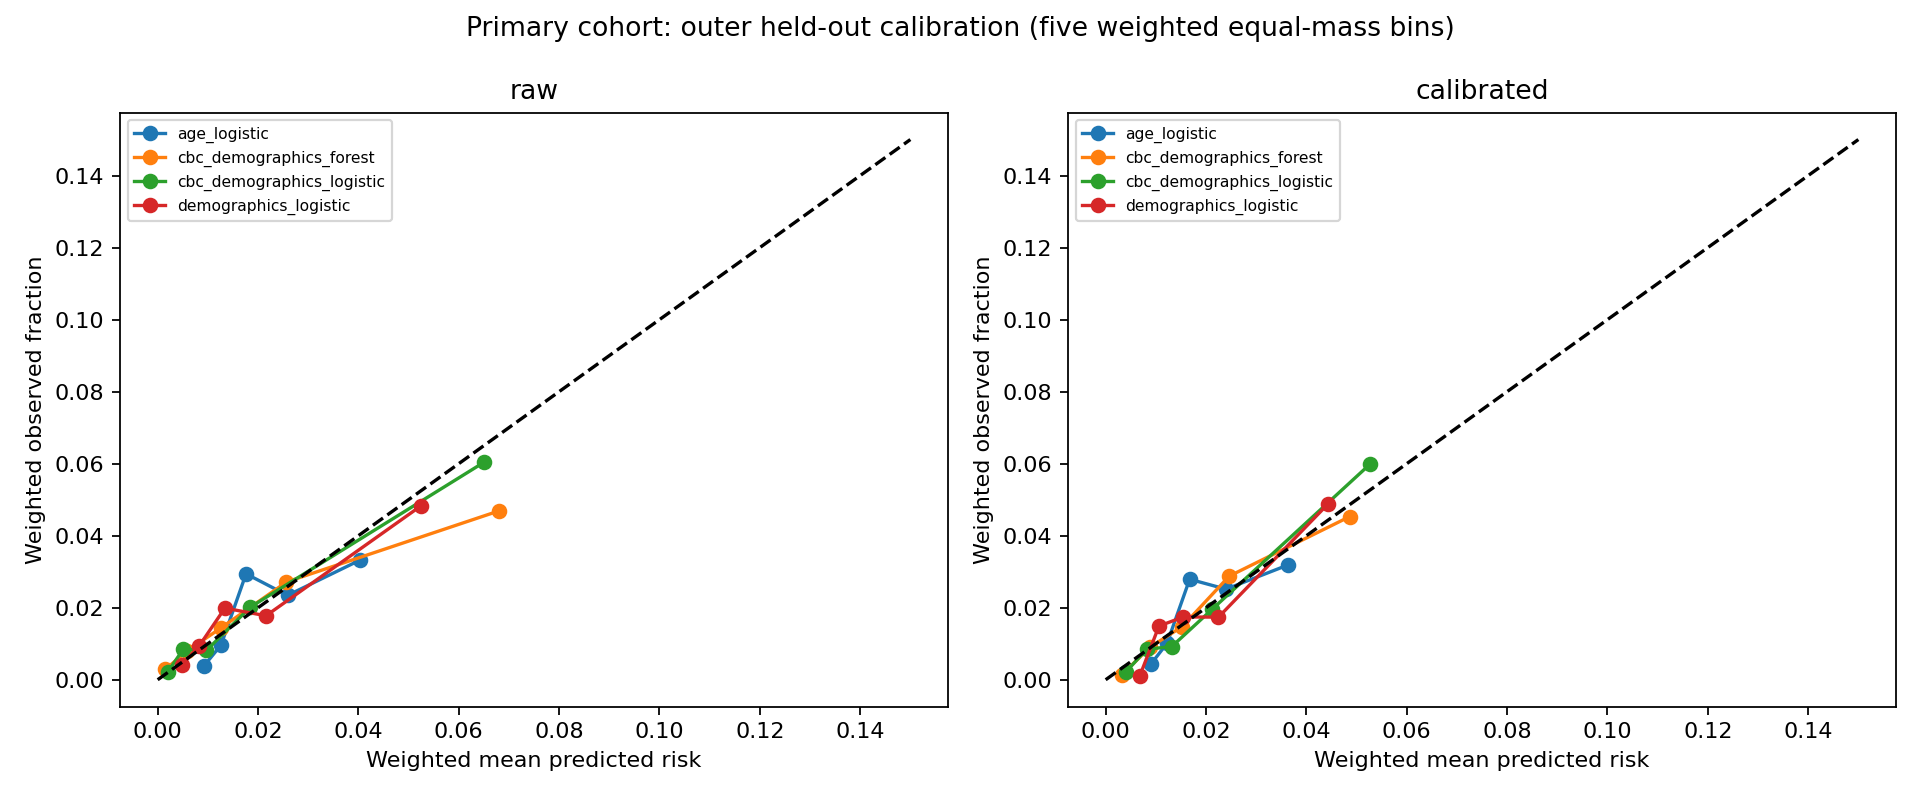

In [5]:
from IPython.display import Image, display
display(Image(filename=str(OUT / 'weighted_calibration.png')))